# DSA 8401 Capstone: Temporal Graph-Enhanced Ensemble (TGEE)

**Procurement integrity risk prioritisation using Kenya PPIP / OCDS data**  
**Student:** Dean Maingi Munywoki | **Registration:** 113719  
**Programme:** MSc Data Science & Analytics, Strathmore University

## Purpose and responsible interpretation

This notebook develops a reproducible research prototype that ranks procurement records for **human review**. It combines structured procurement attributes, tender text, historical temporal deviations, buyer-supplier relationships and (only when disclosure supports it) repeated bidder co-participation patterns.

The available public OCDS records do not provide a verified outcome label for fraud or corruption. The primary TGEE output is therefore an **anomaly / review-priority score**, not a fraud probability or finding. The optional proxy-label experiment is disabled by default. If explicitly enabled, it measures agreement with a transparent rule catalogue only; it is not empirical validation against proven misconduct.

The unit of analysis is a **latest available process snapshot per OCID**. This is a retrospective screening design. Award and contract information may be used for retrospective review, but the resulting model must not be represented as a pre-award real-time prevention tool.

## Notebook map

1. Environment and reproducibility settings
2. OCDS ingestion, provenance and schema-aware extraction
3. Data quality audit and exploratory analysis
4. Point-in-time temporal and buyer-supplier feature engineering
5. Conditional bidder co-participation (hypergraph-inspired) features
6. Chronological evaluation design
7. TGEE branch training and score fusion
8. Baselines, stability, ablation and forensic diagnostics
9. Optional weak-label model comparison (proxy agreement only)
10. Explanations, review queue, artifacts and report outputs

> **Data:** For the FY2025/2026 rebuild, place `2025_2026.json` in `data/raw/`. The notebook explicitly selects this file and filters 1 July 2025 through 30 June 2026. Older extracts are not combined automatically. Synthetic smoke-test data must be run separately and never reported as empirical PPIP results.

## 1. Environment and configuration

In [ ]:
from __future__ import annotations


In [ ]:
import os, re, json, gzip, time, math, hashlib, warnings, itertools, platform
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare, spearmanr


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, average_precision_score,
    matthews_corrcoef, balanced_accuracy_score)
from sklearn.ensemble import StackingClassifier
from sklearn.base import clone
import joblib


In [ ]:
try:
    import networkx as nx
    NETWORKX_AVAILABLE = True
except Exception:
    NETWORKX_AVAILABLE = False


In [ ]:
try:
    from IPython.display import display
except Exception:
    display = print


In [ ]:
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [ ]:
PROJECT_ROOT = Path.cwd()
# Handle execution from the project root or from notebooks/.
if not (PROJECT_ROOT / 'data').exists() and (PROJECT_ROOT.parent / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent


In [ ]:
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
SAMPLE_PATH = PROJECT_ROOT / 'data' / 'sample' / 'synthetic_ocds_releases.json'
# This rebuild is deliberately isolated from the previous all-years TGEE outputs.
FY_LABEL = 'fy2025_2026'
FY_START = pd.Timestamp('2025-07-01', tz='UTC')
FY_END_EXCLUSIVE = pd.Timestamp('2026-07-01', tz='UTC')
SOURCE_FILES = ['2025_2026.json']  # Explicit: never auto-combine older extracts.


In [ ]:
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed' / FY_LABEL
ARTIFACT_DIR = PROJECT_ROOT / 'artifacts' / FY_LABEL
REPORT_DIR = PROJECT_ROOT / 'reports' / FY_LABEL
FIGURE_DIR = REPORT_DIR / 'figures'
TABLE_DIR = REPORT_DIR / 'tables'
for folder in [RAW_DIR, PROCESSED_DIR, ARTIFACT_DIR, REPORT_DIR, FIGURE_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


In [ ]:
# Reproducible, configurable defaults. Tune only through a documented experiment.
CONFIG = {
    'random_state': RANDOM_STATE,
    'test_fraction': 0.20,
    'min_hypergraph_coverage': 0.05,
    'min_hypergraph_records': 50,
    'min_hypergraph_entities': 10,
    'iforest_estimators': 300,
    'review_quantile': 0.90,
    'high_priority_quantile': 0.98,
    'max_proxy_train_rows': 30000,
    'analysis_period': FY_LABEL,
    'run_proxy_classifier': False,
    'run_optional_boosting': False,
}


In [ ]:
print('Python:', platform.python_version())
print('NumPy:', np.__version__, '| Pandas:', pd.__version__)
print('Project root:', PROJECT_ROOT)
print('Raw data folder:', RAW_DIR)
print('NetworkX available:', NETWORKX_AVAILABLE)

## 2. OCDS ingestion and provenance

In [ ]:
def _read_json_or_jsonl(path: Path):
    """Read an OCDS release package, JSONL file, or gzip-compressed JSONL."""
    opener = gzip.open if path.suffix.lower() == '.gz' else open
    with opener(path, 'rt', encoding='utf-8') as handle:
        if path.name.lower().endswith(('.jsonl', '.jsonl.gz')):
            rows = []
            for line_no, line in enumerate(handle, start=1):
                line = line.strip()
                if not line:
                    continue
                obj = json.loads(line)
                if isinstance(obj, dict) and isinstance(obj.get('releases'), list):
                    rows.extend(obj['releases'])
                elif isinstance(obj, dict):
                    rows.append(obj)
            return rows
        obj = json.load(handle)
    if isinstance(obj, dict) and isinstance(obj.get('releases'), list):
        return obj['releases']
    if isinstance(obj, list):
        return obj
    if isinstance(obj, dict):
        return [obj]
    raise ValueError(f'Unsupported OCDS payload in {path}')



In [ ]:
def discover_source_files(raw_dir=RAW_DIR):
    patterns = ['*.json', '*.jsonl', '*.jsonl.gz', '*.gz']
    found = []
    for pattern in patterns:
        found.extend(raw_dir.glob(pattern))
    return sorted(set(p for p in found if p.is_file()))



In [ ]:
# Explicit source selection prevents accidental mixing of unrelated extracts.
missing_sources = [name for name in SOURCE_FILES if not (RAW_DIR / name).is_file()]
if missing_sources:
    raise FileNotFoundError(
        f"Required FY source file(s) missing from {RAW_DIR}: {missing_sources}"
    )


In [ ]:
source_files = [RAW_DIR / name for name in SOURCE_FILES]
DATA_MODE = 'official_fy2025_2026'
all_releases = []
source_manifest = []
for file_path in source_files:
    t0 = time.time()
    file_hash = hashlib.sha256(file_path.read_bytes()).hexdigest()
    loaded = _read_json_or_jsonl(file_path)
    all_releases.extend(loaded)
    source_manifest.append({
        'file': file_path.name,
        'bytes': file_path.stat().st_size,
        'sha256': file_hash,
        'release_rows': len(loaded),
        'load_seconds': round(time.time() - t0, 2)
    })



In [ ]:
print(f'DATA MODE: {DATA_MODE}')
print(f'Releases loaded: {len(all_releases):,}')
print('Source manifest:')
display(pd.DataFrame(source_manifest))
if DATA_MODE == 'synthetic_smoke_test':
    print('WARNING: Synthetic fixture selected. Do not report its results as PPIP empirical findings.')

In [ ]:
def _safe_float(value):
    try:
        if value is None or value == '':
            return np.nan
        return float(value)
    except (TypeError, ValueError):
        return np.nan



In [ ]:
def _dt(value):
    if not value:
        return pd.NaT
    return pd.to_datetime(value, errors='coerce', utc=True)



In [ ]:
def _entity_key(entity):
    """Prefer source identifier; use exact normalised name only as a fallback."""
    if not isinstance(entity, dict):
        return None
    ident = str(entity.get('id') or '').strip()
    name = str(entity.get('name') or '').strip()
    if ident:
        return 'id:' + ident.casefold()
    if name:
        return 'name:' + re.sub(r'\s+', ' ', name.casefold()).strip()
    return None



In [ ]:
def extract_release(release, source_file=''):
    tender = release.get('tender') or {}
    buyer = release.get('buyer') or {}
    parties = release.get('parties') or []
    awards = release.get('awards') or []
    contracts = release.get('contracts') or []
    period = tender.get('tenderPeriod') or {}

    if not buyer:
        buyer = next((p for p in parties if 'buyer' in (p.get('roles') or [])), {})

    tenderer_entities = []
    for party in parties:
        if 'tenderer' in (party.get('roles') or []):
            # Only source IDs support bidder linkage; name-only records remain unlinked.
            party_id = str(party.get('id') or '').strip()
            if party_id:
                tenderer_entities.append('id:' + party_id.casefold())
    tenderer_entities = sorted(set(tenderer_entities))

    supplier_entities, supplier_names = [], []
    supplier_entries = 0
    supplier_ids_missing = 0
    for award in awards:
        for supplier in (award.get('suppliers') or []):
            supplier_entries += 1
            # Do not merge distinct suppliers solely because their names match.
            supplier_id = str(supplier.get('id') or '').strip()
            if supplier_id:
                supplier_entities.append('id:' + supplier_id.casefold())
            else:
                supplier_ids_missing += 1
            if supplier.get('name'):
                supplier_names.append(str(supplier['name']).strip())
    supplier_entities = sorted(set(supplier_entities))
    supplier_names = sorted(set(supplier_names))

    kes_values, currencies = [], set()
    for award in awards:
        value = award.get('value') or {}
        currency = str(value.get('currency') or '').strip().upper()
        amount = _safe_float(value.get('amount'))
        if currency:
            currencies.add(currency)
        if currency == 'KES' and pd.notna(amount) and amount > 0:
            kes_values.append(amount)

    title = str(tender.get('title') or '').strip()
    description = str(tender.get('description') or '').strip()
    buyer_key = _entity_key(buyer)
    buyer_name = str(buyer.get('name') or '').strip()
    buyer_id = str(buyer.get('id') or '').strip()
    if not buyer_key and buyer_name:
        buyer_key = 'name:' + re.sub(r'\s+', ' ', buyer_name.casefold()).strip()

    return {
        'ocid': str(release.get('ocid') or '').strip(),
        'release_id': str(release.get('id') or '').strip(),
        'release_date': _dt(release.get('date')),
        'tender_start': _dt(period.get('startDate')),
        'tender_end': _dt(period.get('endDate')),
        'buyer_id': buyer_id, 'buyer_key': buyer_key, 'buyer_name': buyer_name,
        'procurement_method_raw': str(tender.get('procurementMethod') or '').strip(),
        'category': str(tender.get('mainProcurementCategory') or 'unknown').strip().lower(),
        'main_procurement_category': str(tender.get('mainProcurementCategory') or 'unknown').strip().lower(),
        'title': title, 'description': description,
        'combined_text': (title + ' ' + description).strip(),
        'num_tenderers': len(tenderer_entities) if tenderer_entities else np.nan,
        'tenderer_count_known': int(bool(tenderer_entities)),
        'tenderer_keys': tenderer_entities,
        'supplier_keys': supplier_entities,
        'supplier_names': supplier_names,
        'supplier_entries': supplier_entries,
        'supplier_ids_missing': supplier_ids_missing,
        'awards_count': len(awards), 'contracts_count': len(contracts),
        'award_value_kes': float(sum(kes_values)) if kes_values else np.nan,
        'kes_award_components': len(kes_values),
        'award_value_missing_or_nonpositive': int(len(kes_values) == 0),
        'award_currencies': '|'.join(sorted(currencies)),
        'mixed_or_non_kes_currency': int(any(c != 'KES' for c in currencies)),
        'source_file': source_file,
    }



In [ ]:
extracted = []
for release in all_releases:
    extracted.append(extract_release(release))
df = pd.DataFrame(extracted)
raw_extracted_rows = len(df)
if df.empty:
    raise ValueError('No usable OCDS releases were extracted.')


In [ ]:
# FY cohort selection uses the release date, falling back to tender start only when absent.
df['event_date'] = df['release_date'].fillna(df['tender_start'])
fy_mask = df['event_date'].ge(FY_START) & df['event_date'].lt(FY_END_EXCLUSIVE)
df = df.loc[fy_mask].copy().reset_index(drop=True)
if df.empty:
    raise ValueError('No records fall within the FY2025/2026 analysis period.')


In [ ]:
# The FY extract was independently audited: one release per OCID. Fail rather than silently
# collapse duplicate processes, because repeated OCIDs require a documented snapshot policy.
missing_ocid = df['ocid'].isna() | df['ocid'].astype(str).str.strip().eq('')
duplicate_ocid = df.loc[~missing_ocid, 'ocid'].duplicated(keep=False)
if missing_ocid.any() or duplicate_ocid.any():
    raise ValueError(
        f"FY cohort integrity check failed: missing OCIDs={int(missing_ocid.sum())}, "
        f"duplicate-OCID rows={int(duplicate_ocid.sum())}. Review source before modelling."
    )


In [ ]:
# A process can have several OCDS releases. For this retrospective snapshot analysis,
# retain its latest release version; preserve records without OCIDs using release IDs.
fallback_id = df['release_id'].where(df['release_id'].ne(''), 'row-' + df.index.astype(str))
df['process_key'] = np.where(df['ocid'].ne(''), df['ocid'], 'release:' + fallback_id.astype(str))
df = df.sort_values(['event_date','release_date'], na_position='first').drop_duplicates('process_key', keep='last')
df = df.reset_index(drop=True)
fy_cohort_release_rows = len(df)
collapsed_release_revisions = 0  # Unique OCID audit confirms one release per FY process.


In [ ]:
print('FY cohort:', FY_LABEL)
print('Source releases:', raw_extracted_rows)
print('FY process snapshots:', f'{len(df):,}')
print('Unique OCIDs verified:', df['ocid'].nunique())
display(df[['ocid','event_date','buyer_name','procurement_method_raw','category','num_tenderers','award_value_kes']].head())

## 3. Cleaning, quality audit and exploratory analysis

In [ ]:
# Preserve unknown values as unknown; do not convert missing bidder disclosure into zero bidders.
method_map = {
    'open':'open', 'selective':'selective', 'direct':'direct',
    'requestforquotation':'direct', 'quotation':'direct',
    'speciallypermitted':'direct', 'frameworkagreement':'selective',
    'alternativeselection':'selective', 'communityparticipation':'selective',
    'communityparticipartion':'selective'
}
df['procurement_method'] = (
    df['procurement_method_raw'].str.lower().str.replace(r'[^a-z]', '', regex=True)
      .map(method_map).fillna('other')
)
df['duration_days'] = (df['tender_end'] - df['tender_start']).dt.total_seconds() / 86400
# Invalid or reversed tender periods are retained as missing with a separate quality flag.
df['invalid_tender_period'] = ((df['duration_days'] <= 0) | (df['duration_days'] > 730)).fillna(False).astype(int)
df['missing_tender_period'] = df[['tender_start','tender_end']].isna().any(axis=1).astype(int)
df['invalid_tender_date_order'] = (df['duration_days'] <= 0).fillna(False).astype(int)
df.loc[df['invalid_tender_period'].eq(1), 'duration_days'] = np.nan


In [ ]:
df['log_award_value_kes'] = np.log1p(df['award_value_kes'].where(df['award_value_kes'] >= 0))
df['release_month'] = df['event_date'].dt.month
df['release_dow'] = df['event_date'].dt.dayofweek
df['fiscal_year'] = np.where(df['event_date'].dt.month >= 7, df['event_date'].dt.year, df['event_date'].dt.year - 1)
df['flag_fy_end'] = df['event_date'].dt.month.isin([5,6]).astype(int)


In [ ]:
title_lower = df['combined_text'].fillna('').str.lower()
df['is_emergency_title'] = title_lower.str.contains(r'emergency|urgent|crisis|pandemic', regex=True).astype(int)
df['is_construction_title'] = title_lower.str.contains(r'construct|road|bridge|rehabilitat|infrastructure|building', regex=True).astype(int)
df['is_it_title'] = title_lower.str.contains(r'ict|software|computer|system|technology|network', regex=True).astype(int)
df['is_medical_title'] = title_lower.str.contains(r'medical|health|drug|medicine|hospital|clinical', regex=True).astype(int)


In [ ]:
df['is_direct'] = (df['procurement_method'] == 'direct').astype(int)
df['is_open'] = (df['procurement_method'] == 'open').astype(int)
df['is_selective'] = (df['procurement_method'] == 'selective').astype(int)
df['flag_flash_tender'] = (df['duration_days'] < 7).fillna(False).astype(int)
df['flag_single_tenderer'] = ((df['tenderer_count_known'] == 1) & (df['num_tenderers'] == 1)).astype(int)
df['flag_competition_unknown'] = (df['tenderer_count_known'] == 0).astype(int)


In [ ]:
quality_rows = [
    ('raw_extracted_release_rows', raw_extracted_rows, 'Release rows extracted before selecting the latest process snapshot'),
    ('collapsed_prior_release_versions', collapsed_release_revisions, 'Earlier releases excluded when retaining one latest snapshot per process'),
    ('process_snapshots', len(df), 'Latest process snapshot per OCID / fallback release identifier'),
    ('missing_event_date', int(df['event_date'].isna().sum()), 'No release date or tender start date'),
    ('missing_buyer_key', int(df['buyer_key'].isna().sum()), 'Buyer identifier and name both absent'),
    ('missing_supplier_entities', int(df['supplier_keys'].apply(len).eq(0).sum()), 'No supplier with a source identifier in award data'),
    ('supplier_entries_missing_id', int(df['supplier_ids_missing'].sum()), 'Supplier entries without a source ID; excluded from relationship linkage'),
    ('records_without_positive_kes_award', int(df['award_value_missing_or_nonpositive'].sum()), 'No positive KES award amount available for financial features'),
    ('missing_tender_period_rows', int(df['missing_tender_period'].sum()), 'At least one tender period boundary is absent'),
    ('tenderer_identity_coverage_pct', round(df['tenderer_count_known'].mean()*100,2), 'Share with at least one identifiable tenderer'),
    ('multi_tenderer_records', int(df['num_tenderers'].ge(2).sum()), 'Records with at least two identifiable tenderers'),
    ('missing_tender_period_pct', round(df[['tender_start','tender_end']].isna().any(axis=1).mean()*100,2), 'At least one tender period boundary missing'),
    ('invalid_tender_periods', int(df['invalid_tender_period'].sum()), 'Zero, negative or implausibly long periods'),
    ('invalid_tender_date_order', int(df['invalid_tender_date_order'].sum()), 'Tender end date is not after tender start date'),
    ('KES_award_value_coverage_pct', round(df['award_value_kes'].notna().mean()*100,2), 'At least one award value explicitly denominated in KES'),
    ('non_KES_or_mixed_currency_records', int(df['mixed_or_non_kes_currency'].sum()), 'Award values include a non-KES currency'),
    ('duplicate_process_keys_remaining', int(df['process_key'].duplicated().sum()), 'Should be zero after snapshot selection'),
]
quality_audit = pd.DataFrame(quality_rows, columns=['check','value','interpretation'])
quality_audit.to_csv(TABLE_DIR/'data_quality_audit.csv', index=False)
display(quality_audit)


In [ ]:
print('Date range:', df['event_date'].min(), 'to', df['event_date'].max())
print('Procurement methods:')
display(df['procurement_method'].value_counts(dropna=False).rename_axis('method').to_frame('records'))

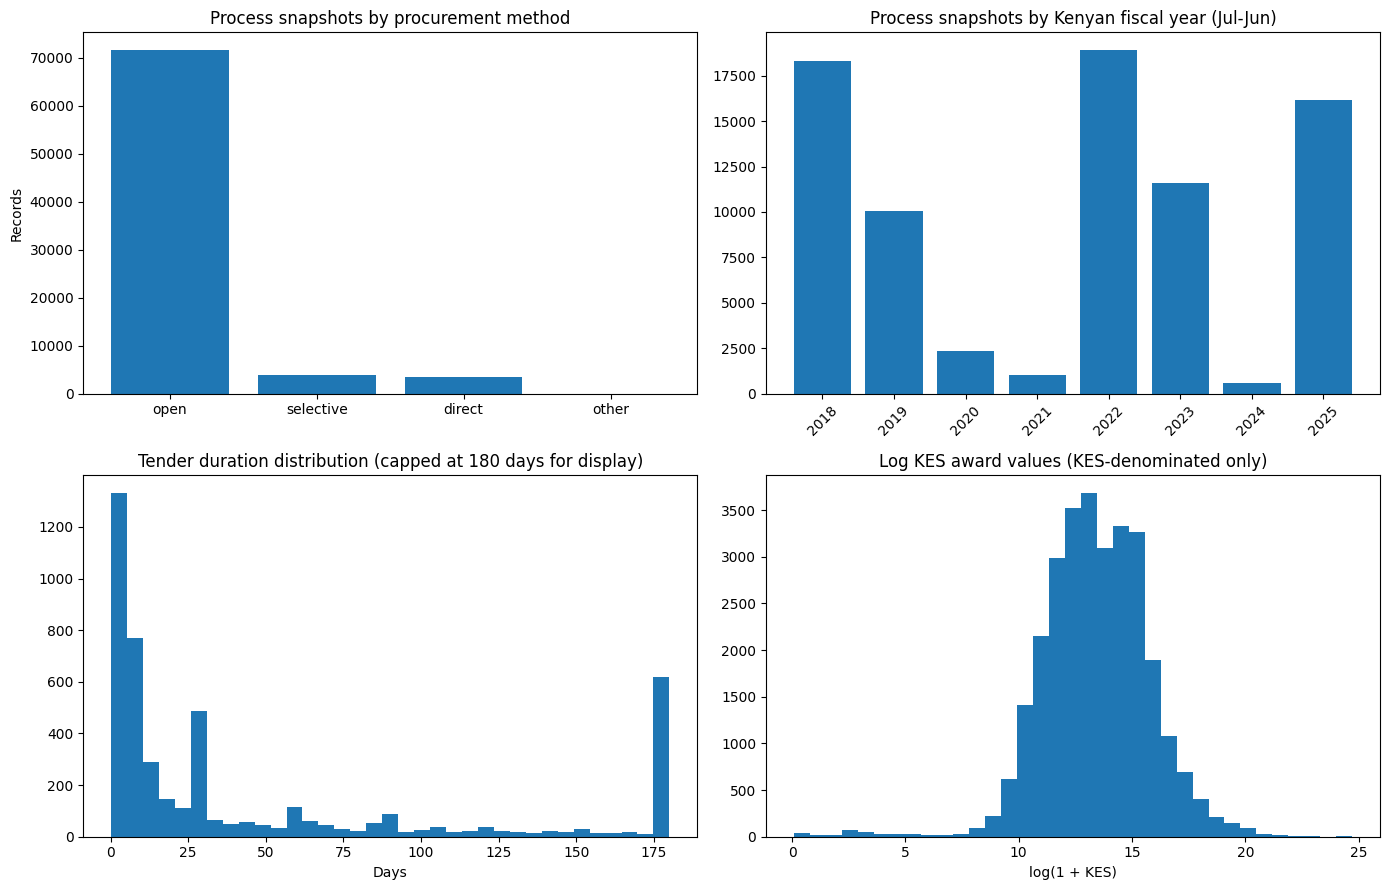

In [5]:
# Compact EDA
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
method_counts = df['procurement_method'].value_counts()
axes[0,0].bar(method_counts.index, method_counts.values)
axes[0,0].set_title('Process snapshots by procurement method')
axes[0,0].set_ylabel('Records')

fy_counts = df['fiscal_year'].dropna().astype(int).value_counts().sort_index()
axes[0,1].bar(fy_counts.index.astype(str), fy_counts.values)
axes[0,1].set_title('Process snapshots by Kenyan fiscal year (Jul-Jun)')
axes[0,1].tick_params(axis='x', rotation=45)

valid_duration = df['duration_days'].dropna().clip(upper=180)
axes[1,0].hist(valid_duration, bins=35)
axes[1,0].set_title('Tender duration distribution (capped at 180 days for display)')
axes[1,0].set_xlabel('Days')

valid_values = df['log_award_value_kes'].dropna()
axes[1,1].hist(valid_values, bins=35)
axes[1,1].set_title('Log KES award values (KES-denominated only)')
axes[1,1].set_xlabel('log(1 + KES)')

plt.tight_layout()
plt.savefig(FIGURE_DIR/'eda_overview.png', dpi=160, bbox_inches='tight')
plt.show()

In [6]:
# Benford's first-digit diagnostic is run only for positive KES values and adequate samples.
benford_expected = np.array([np.log10(1 + 1/d) for d in range(1,10)])
benford_rows = []
for method, group in df.groupby('procurement_method'):
    values = group['award_value_kes'].dropna()
    values = values[values > 0]
    digits = values.astype(int).astype(str).str.lstrip('0').str[0]
    digits = pd.to_numeric(digits, errors='coerce').dropna()
    digits = digits[digits.between(1,9)].astype(int)
    if len(digits) < 100:
        benford_rows.append({'procurement_method':method,'n':len(digits),'chi2':np.nan,'p_value':np.nan,
                             'status':'Insufficient sample for this diagnostic'})
        continue
    observed = np.array([(digits == d).sum() for d in range(1,10)], dtype=float)
    expected = benford_expected * len(digits)
    stat, p_value = chisquare(observed, f_exp=expected)
    benford_rows.append({'procurement_method':method,'n':len(digits),'chi2':stat,'p_value':p_value,
                         'status':'Exploratory deviation test only'})
benford_results = pd.DataFrame(benford_rows)
benford_results.to_csv(TABLE_DIR/'benford_by_method.csv', index=False)
display(benford_results)
print('Benford caution: procurement values may be truncated, regulated, currency-mixed or category-specific; a small p-value is not evidence of manipulation.')

,procurement_method,n,chi2,p_value,status
0,direct,1214,21.474516,5.988224e-03,Exploratory deviation test only
1,open,27116,254.541934,1.876009e-50,Exploratory deviation test only
2,other,6,NaN,NaN,Insufficient sample for this diagnostic
3,selective,969,57.702124,1.313298e-09,Exploratory deviation test only


Benford caution: procurement values may be truncated, regulated, currency-mixed or category-specific; a small p-value is not evidence of manipulation.


## 4. Point-in-time temporal and buyer-supplier feature engineering

In [ ]:
# Sort before calculating any historical features. Each row sees only earlier rows.
df = df.sort_values(['event_date','release_id'], na_position='last').reset_index(drop=True)


In [ ]:
# Temporal deviation: compare current values with an exponentially weighted baseline
# from prior records in the same procurement-method/category stratum.
for source_col, prefix in [('duration_days','duration'), ('log_award_value_kes','value')]:
    grouped = df.groupby(['procurement_method','category'], dropna=False)[source_col]
    hist_mean = grouped.transform(lambda s: s.shift(1).ewm(span=30, min_periods=8, adjust=False).mean())
    hist_std = grouped.transform(lambda s: s.shift(1).ewm(span=30, min_periods=8, adjust=False).std())
    z = (df[source_col] - hist_mean) / hist_std.replace(0, np.nan)
    df[f'{prefix}_historical_z'] = z.replace([np.inf,-np.inf], np.nan)
    df[f'{prefix}_historical_abs_z'] = df[f'{prefix}_historical_z'].abs().clip(upper=10)


In [ ]:
df['temporal_history_available'] = df[['duration_historical_abs_z','value_historical_abs_z']].notna().any(axis=1).astype(int)
df['temporal_raw_score'] = df[['duration_historical_abs_z','value_historical_abs_z']].mean(axis=1, skipna=True).fillna(0)


In [ ]:
# Buyer-supplier graph history. Features are computed before updating the graph with
# the current process, so the current edge and future relationships cannot leak in.
buyer_supplier_counts = Counter()
buyer_supplier_total = Counter()
supplier_buyer_counts = defaultdict(Counter)
supplier_award_counts = Counter()
buyer_supplier_degree = Counter()
buyer_award_counts = Counter()
buyer_supplier_features = []


In [ ]:
for row in df.itertuples(index=False):
    buyer = row.buyer_key if isinstance(row.buyer_key, str) and row.buyer_key else None
    suppliers = list(row.supplier_keys) if isinstance(row.supplier_keys, list) else []
    suppliers = sorted(set(suppliers))

    prior_pair_counts = []
    prior_supplier_buyer_degrees = []
    prior_supplier_award_counts = []
    prior_supplier_hhi = []
    for supplier in suppliers:
        if buyer:
            prior_pair_counts.append(buyer_supplier_counts[(buyer,supplier)])
        by_buyer = supplier_buyer_counts[supplier]
        total_hist = sum(by_buyer.values())
        hhi = (sum((count/total_hist)**2 for count in by_buyer.values()) if total_hist else 0.0)
        prior_supplier_buyer_degrees.append(len(by_buyer))
        prior_supplier_award_counts.append(supplier_award_counts[supplier])
        prior_supplier_hhi.append(hhi)

    buyer_prior_supplier_count = buyer_supplier_degree[buyer] if buyer else 0
    buyer_prior_award_count = buyer_award_counts[buyer] if buyer else 0
    vals = {
        'buyer_prior_supplier_count': buyer_prior_supplier_count,
        'buyer_prior_award_count': buyer_prior_award_count,
        'buyer_supplier_prior_count': max(prior_pair_counts, default=0),
        'supplier_prior_buyer_count': max(prior_supplier_buyer_degrees, default=0),
        'supplier_prior_award_count': max(prior_supplier_award_counts, default=0),
        'supplier_prior_buyer_hhi': max(prior_supplier_hhi, default=0.0),
    }
    vals['pair_prior_share'] = (vals['buyer_supplier_prior_count'] / max(1, vals['buyer_prior_award_count']))
    vals['graph_raw_score'] = (
        np.log1p(vals['buyer_supplier_prior_count']) +
        np.log1p(vals['supplier_prior_buyer_count']) +
        vals['supplier_prior_buyer_hhi']
    )
    buyer_supplier_features.append(vals)

    # Update state after extracting the current row's prior-history features.
    if buyer:
        for supplier in suppliers:
            if buyer_supplier_counts[(buyer,supplier)] == 0:
                buyer_supplier_degree[buyer] += 1
            buyer_supplier_counts[(buyer,supplier)] += 1
            buyer_supplier_total[(buyer,supplier)] += 1
            buyer_award_counts[buyer] += 1
            supplier_buyer_counts[supplier][buyer] += 1
            supplier_award_counts[supplier] += 1


In [ ]:
graph_feature_df = pd.DataFrame(buyer_supplier_features, index=df.index)
df = pd.concat([df, graph_feature_df], axis=1)


In [ ]:
# Transparent review indicators; these are signals, not labels or findings.
df['signal_short_tender'] = (df['duration_days'] < 7).fillna(False).astype(int)
df['signal_single_known_tenderer'] = ((df['tenderer_count_known'] == 1) & (df['num_tenderers'] == 1)).astype(int)
df['signal_repeated_buyer_supplier'] = (df['buyer_supplier_prior_count'] >= 3).astype(int)
df['signal_high_supplier_reach'] = (df['supplier_prior_buyer_count'] >= 5).astype(int)


In [ ]:
print('Temporal and graph history features generated.')
display(df[['event_date','buyer_name','supplier_names','duration_days','duration_historical_abs_z',
            'buyer_supplier_prior_count','supplier_prior_buyer_count','graph_raw_score']].head(12))

## 5. Conditional bidder co-participation branch

In [ ]:
# Each tender with >=2 reliably identified tenderers is a hyperedge candidate.
# We do not infer missing competitors and do not construct bidder relationships from award suppliers.
co_bid_counts = Counter()
bidder_tender_counts = Counter()
hypergraph_features = []
multi_bid_rows = 0
all_bidder_keys = set()


In [ ]:
for row in df.itertuples(index=False):
    tenderers = list(row.tenderer_keys) if isinstance(row.tenderer_keys, list) else []
    tenderers = sorted(set(tenderers))
    all_bidder_keys.update(tenderers)
    if len(tenderers) >= 2:
        multi_bid_rows += 1
    previous_activity = [bidder_tender_counts[b] for b in tenderers]
    pairs = list(itertools.combinations(tenderers, 2))
    prior_pair_activity = [co_bid_counts[pair] for pair in pairs]
    hypergraph_features.append({
        'tenderer_count': len(tenderers) if tenderers else np.nan,
        'tenderer_history_max': max(previous_activity, default=0),
        'cobidder_repeat_max': max(prior_pair_activity, default=0),
        'cobidder_repeat_mean': float(np.mean(prior_pair_activity)) if prior_pair_activity else 0.0,
        'hypergraph_history_available': int(bool(tenderers)),
    })
    for bidder in tenderers:
        bidder_tender_counts[bidder] += 1
    for pair in pairs:
        co_bid_counts[pair] += 1


In [ ]:
df = pd.concat([df, pd.DataFrame(hypergraph_features, index=df.index)], axis=1)
hypergraph_coverage = multi_bid_rows / max(1,len(df))
hypergraph_eligible = (
    hypergraph_coverage >= CONFIG['min_hypergraph_coverage'] and
    multi_bid_rows >= CONFIG['min_hypergraph_records'] and
    len(all_bidder_keys) >= CONFIG['min_hypergraph_entities']
)
print(f'Multi-tenderer identity coverage: {hypergraph_coverage:.1%} ({multi_bid_rows:,} records)')
print(f'Identified tenderer entities: {len(all_bidder_keys):,}')
print('Conditional bidder co-participation branch:', 'ENABLED' if hypergraph_eligible else 'DISABLED — disclosure coverage is insufficient')

## 6. Chronological train / holdout design

In [ ]:
# Chronological split by event date; do not use stratified random splitting for the main evaluation.
valid_date = df['event_date'].notna()
if valid_date.sum() < 20:
    raise ValueError('At least 20 dated process snapshots are needed for chronological evaluation.')
ordered_dates = df.loc[valid_date, 'event_date'].sort_values()
split_position = int((1 - CONFIG['test_fraction']) * len(ordered_dates))
split_position = min(max(split_position, 1), len(ordered_dates)-1)
cutoff_date = ordered_dates.iloc[split_position]
train_mask = valid_date & (df['event_date'] < cutoff_date)
test_mask = valid_date & (df['event_date'] >= cutoff_date)
train_idx = np.flatnonzero(train_mask.to_numpy())
test_idx = np.flatnonzero(test_mask.to_numpy())
if len(train_idx) < 30 or len(test_idx) < 10:
    raise ValueError('Chronological split produced too few rows. Check date coverage and CONFIG.')


In [ ]:
print('Chronological cutoff:', cutoff_date)
print(f'Train: {len(train_idx):,} | Holdout: {len(test_idx):,}')
print('Train period:', df.loc[train_mask,'event_date'].min(), 'to', df.loc[train_mask,'event_date'].max())
print('Holdout period:', df.loc[test_mask,'event_date'].min(), 'to', df.loc[test_mask,'event_date'].max())


In [ ]:
# Static buyer-supplier bipartite graph diagnostics on the training period only.
# The fitted TGEE branch uses the stricter point-in-time history features above.
if NETWORKX_AVAILABLE:
    train_graph = nx.Graph()
    for row in df.loc[train_idx].itertuples(index=False):
        buyer = row.buyer_key if isinstance(row.buyer_key, str) and row.buyer_key else None
        suppliers = list(row.supplier_keys) if isinstance(row.supplier_keys, list) else []
        if buyer:
            for supplier in set(suppliers):
                buyer_node = 'buyer::' + buyer
                supplier_node = 'supplier::' + supplier
                train_graph.add_node(buyer_node, entity_type='buyer')
                train_graph.add_node(supplier_node, entity_type='supplier')
                train_graph.add_edge(buyer_node, supplier_node)
    graph_summary = pd.DataFrame([{
        'training_graph_nodes': train_graph.number_of_nodes(),
        'training_graph_edges': train_graph.number_of_edges(),
        'buyer_nodes': sum(1 for _,d in train_graph.nodes(data=True) if d.get('entity_type')=='buyer'),
        'supplier_nodes': sum(1 for _,d in train_graph.nodes(data=True) if d.get('entity_type')=='supplier'),
        'connected_components': nx.number_connected_components(train_graph),
        'largest_component_nodes': max((len(c) for c in nx.connected_components(train_graph)), default=0),
    }])
else:
    graph_summary = pd.DataFrame([{'status':'NetworkX unavailable; dynamic adjacency features still used'}])
graph_summary.to_csv(TABLE_DIR/'bipartite_graph_diagnostics.csv', index=False)
display(graph_summary)


## 7. TGEE branch definitions and model fitting

In [ ]:
TABULAR_NUMERIC = [
    'duration_days','log_award_value_kes','num_tenderers','tenderer_count_known',
    'awards_count','contracts_count','invalid_tender_period','is_direct','is_open','is_selective',
    'release_month','release_dow','fiscal_year','flag_fy_end',
    'is_emergency_title','is_construction_title','is_it_title','is_medical_title'
]
TABULAR_CATEGORICAL = ['procurement_method','category','main_procurement_category']
TEMPORAL_FEATURES = ['duration_historical_abs_z','value_historical_abs_z','temporal_history_available']
GRAPH_FEATURES = ['buyer_prior_supplier_count','buyer_prior_award_count','buyer_supplier_prior_count',
                  'supplier_prior_buyer_count','supplier_prior_award_count','supplier_prior_buyer_hhi','pair_prior_share']
HYPERGRAPH_FEATURES = ['tenderer_count','tenderer_history_max','cobidder_repeat_max','cobidder_repeat_mean',
                       'hypergraph_history_available']



In [ ]:
def make_iforest_pipeline(numeric_cols, categorical_cols=None, seed=RANDOM_STATE):
    categorical_cols = categorical_cols or []
    transformers = []
    if numeric_cols:
        numeric_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
            ('scaler', RobustScaler()),
        ])
        transformers.append(('numeric', numeric_pipe, numeric_cols))
    if categorical_cols:
        category_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore')),
        ])
        transformers.append(('categorical', category_pipe, categorical_cols))
    preprocess = ColumnTransformer(transformers, remainder='drop')
    return Pipeline([
        ('preprocess', preprocess),
        ('detector', IsolationForest(n_estimators=CONFIG['iforest_estimators'],
                                     contamination='auto', random_state=seed, n_jobs=-1))
    ])



In [ ]:
def percentile_scores(reference, values):
    reference = np.asarray(reference, dtype=float)
    reference = reference[np.isfinite(reference)]
    values = np.asarray(values, dtype=float)
    if len(reference) == 0:
        return np.full(len(values), 0.5)
    ref = np.sort(reference)
    out = np.full(len(values), 0.5, dtype=float)
    good = np.isfinite(values)
    out[good] = np.searchsorted(ref, values[good], side='right') / len(ref)
    return np.clip(out, 0, 1)



In [ ]:
def fit_if_branch(name, feature_cols, numeric_cols, categorical_cols=None):
    train_frame = df.loc[train_idx, feature_cols].copy()
    holdout_frame = df.loc[test_idx, feature_cols].copy()
    model = make_iforest_pipeline(numeric_cols, categorical_cols, CONFIG['random_state'])
    model.fit(train_frame)
    train_raw = -model.score_samples(train_frame)
    holdout_raw = -model.score_samples(holdout_frame)
    return {
        'model': model,
        'train_raw': train_raw,
        'holdout_raw': holdout_raw,
        'reference': np.sort(train_raw),
        'train_percentile': percentile_scores(train_raw, train_raw),
        'holdout_percentile': percentile_scores(train_raw, holdout_raw),
        'feature_cols': feature_cols,
    }



In [ ]:
branch_results = {}
# Structured tabular branch
branch_results['tabular'] = fit_if_branch('tabular', TABULAR_NUMERIC + TABULAR_CATEGORICAL,
                                          TABULAR_NUMERIC, TABULAR_CATEGORICAL)


In [ ]:
# Temporal branch uses only historical deviation features.
branch_results['temporal'] = fit_if_branch('temporal', TEMPORAL_FEATURES, TEMPORAL_FEATURES)
# Buyer-supplier branch uses only prior history; there is no current/future edge contribution.
branch_results['graph'] = fit_if_branch('graph', GRAPH_FEATURES, GRAPH_FEATURES)


In [ ]:
# Tender-text novelty branch. Fit vocabulary and SVD on the earlier period only.
text_train = df.loc[train_idx, 'combined_text'].fillna('').astype(str)
text_test = df.loc[test_idx, 'combined_text'].fillna('').astype(str)
text_branch_active = text_train.str.len().gt(0).sum() >= 30 and text_train.nunique() >= 10
if text_branch_active:
    vectorizer = TfidfVectorizer(max_features=1500, min_df=2, max_df=0.98, ngram_range=(1,2), sublinear_tf=True)
    X_text_train_sparse = vectorizer.fit_transform(text_train)
    X_text_test_sparse = vectorizer.transform(text_test)
    if X_text_train_sparse.shape[1] >= 2 and len(train_idx) >= 20:
        n_components = min(24, X_text_train_sparse.shape[1]-1, len(train_idx)-1)
        text_svd = TruncatedSVD(n_components=n_components, random_state=RANDOM_STATE)
        X_text_train = text_svd.fit_transform(X_text_train_sparse)
        X_text_test = text_svd.transform(X_text_test_sparse)
        text_detector = IsolationForest(n_estimators=CONFIG['iforest_estimators'], contamination='auto',
                                        random_state=RANDOM_STATE, n_jobs=-1)
        text_detector.fit(X_text_train)
        tr_raw = -text_detector.score_samples(X_text_train)
        te_raw = -text_detector.score_samples(X_text_test)
        branch_results['text'] = {
            'model': text_detector, 'vectorizer': vectorizer, 'svd': text_svd,
            'train_raw': tr_raw, 'holdout_raw': te_raw,
            'reference': np.sort(tr_raw),
            'train_percentile': percentile_scores(tr_raw,tr_raw),
            'holdout_percentile': percentile_scores(tr_raw,te_raw),
            'feature_cols': ['combined_text'],
        }
else:
    print('Text branch disabled: insufficient title/description coverage or diversity.')


In [ ]:
# Bidder co-participation branch is included only when the source passes the coverage test.
if hypergraph_eligible:
    branch_results['hypergraph'] = fit_if_branch('hypergraph', HYPERGRAPH_FEATURES, HYPERGRAPH_FEATURES)
else:
    print('Hypergraph branch skipped; do not infer missing tenderer identities.')


In [ ]:
# Pre-specified design weights; unavailable branches are removed and active weights renormalised.
DEFAULT_WEIGHTS = {'tabular':0.30, 'text':0.15, 'temporal':0.25, 'graph':0.20, 'hypergraph':0.10}
active_branches = list(branch_results.keys())
weight_total = sum(DEFAULT_WEIGHTS[b] for b in active_branches)
active_weights = {b: DEFAULT_WEIGHTS[b]/weight_total for b in active_branches}
print('Active TGEE branches and normalised weights:', active_weights)

In [ ]:
# Assemble aligned branch percentiles for train and chronological holdout.
train_component_scores = pd.DataFrame(index=train_idx)
holdout_component_scores = pd.DataFrame(index=test_idx)
for branch_name, result in branch_results.items():
    train_component_scores[branch_name] = result['train_percentile']
    holdout_component_scores[branch_name] = result['holdout_percentile']


In [ ]:
train_tgee = sum(train_component_scores[b] * active_weights[b] for b in active_branches)
holdout_tgee = sum(holdout_component_scores[b] * active_weights[b] for b in active_branches)


In [ ]:
# Thresholds come only from the training-period score distribution.
review_threshold = float(np.quantile(train_tgee, CONFIG['review_quantile']))
high_threshold = float(np.quantile(train_tgee, CONFIG['high_priority_quantile']))


In [ ]:
all_scores = pd.DataFrame(index=df.index)
for branch in active_branches:
    all_scores[branch + '_score'] = np.nan
    all_scores.loc[train_idx, branch + '_score'] = train_component_scores[branch].values
    all_scores.loc[test_idx, branch + '_score'] = holdout_component_scores[branch].values
all_scores['tgee_priority_score'] = np.nan
all_scores.loc[train_idx, 'tgee_priority_score'] = np.asarray(train_tgee)
all_scores.loc[test_idx, 'tgee_priority_score'] = np.asarray(holdout_tgee)
all_scores['data_split'] = 'unscored'
all_scores.loc[train_idx,'data_split'] = 'train_reference'
all_scores.loc[test_idx,'data_split'] = 'chronological_holdout'
all_scores['review_band'] = np.select(
    [all_scores['tgee_priority_score'] >= high_threshold,
     all_scores['tgee_priority_score'] >= review_threshold],
    ['high_priority','review'], default='routine'
)
all_scores.loc[all_scores['tgee_priority_score'].isna(), 'review_band'] = 'unscored'


In [ ]:
# Dominant branch gives a concise explanation of which model component drove a score.
weighted_components = pd.DataFrame({b: all_scores[b+'_score']*active_weights[b] for b in active_branches})
all_scores['dominant_component'] = weighted_components.idxmax(axis=1)


In [ ]:
scored_df = pd.concat([df, all_scores], axis=1)
print('Training-only review threshold:', round(review_threshold,4))
print('Training-only high-priority threshold:', round(high_threshold,4))
display(scored_df.loc[test_idx, ['ocid','event_date','tgee_priority_score','review_band','dominant_component']]
        .sort_values('tgee_priority_score', ascending=False).head(10))

## 8. Baselines, stability and ablation

In [ ]:
# Isolation Forest and Local Outlier Factor provide simple tabular-only references.
# Comparison is rank-based because verified integrity outcomes are unavailable.
tab_train = df.loc[train_idx, TABULAR_NUMERIC].copy()
tab_test = df.loc[test_idx, TABULAR_NUMERIC].copy()
num_preprocess = Pipeline([('imputer',SimpleImputer(strategy='median', add_indicator=True)),('scaler',RobustScaler())])
Xtr_num = num_preprocess.fit_transform(tab_train)
Xte_num = num_preprocess.transform(tab_test)


In [ ]:
# LOF has quadratic-like neighbour-search costs on some feature spaces. For large
# datasets, fit and compare it on a fixed seeded sample rather than attempting an
# all-record nearest-neighbour fit that can exhaust memory/time.
lof_train_limit = min(8000, len(train_idx))
lof_holdout_limit = min(10000, len(test_idx))
rng = np.random.default_rng(RANDOM_STATE)
lof_train_sel = np.sort(rng.choice(len(train_idx), size=lof_train_limit, replace=False))
lof_test_sel = np.sort(rng.choice(len(test_idx), size=lof_holdout_limit, replace=False))
lof_neighbors = min(35, max(5, lof_train_limit//10))
lof_model = LocalOutlierFactor(n_neighbors=lof_neighbors, novelty=True, contamination='auto')
lof_model.fit(Xtr_num[lof_train_sel])
lof_train_raw = -lof_model.score_samples(Xtr_num[lof_train_sel])
lof_holdout_raw = -lof_model.score_samples(Xte_num[lof_test_sel])
lof_reference = np.sort(lof_train_raw)
lof_holdout_pct = percentile_scores(lof_reference, lof_holdout_raw)


In [ ]:
tab_if_holdout = holdout_component_scores['tabular'].to_numpy()
tgee_holdout = np.asarray(holdout_tgee)


In [ ]:
def _topk_overlap(a, b, k):
    ia = set(np.argsort(np.asarray(a))[-k:])
    ib = set(np.argsort(np.asarray(b))[-k:])
    return len(ia & ib) / max(1,k)


In [ ]:
k_eval = max(1, min(100, int(math.ceil(0.05*len(test_idx)))))
k_eval_lof = max(1, min(100, int(math.ceil(0.05*len(lof_test_sel)))))
base_rows = [
    {'model':'Isolation Forest (tabular)',
     'spearman_vs_tgee':float(spearmanr(tab_if_holdout,tgee_holdout).statistic),
     'top_k_overlap_with_tgee':_topk_overlap(tab_if_holdout,tgee_holdout,k_eval),
     'top_k':k_eval,'evaluation_population':len(test_idx)},
    {'model':'Local Outlier Factor (tabular, seeded sample)',
     'spearman_vs_tgee':float(spearmanr(lof_holdout_pct,tgee_holdout[lof_test_sel]).statistic),
     'top_k_overlap_with_tgee':_topk_overlap(lof_holdout_pct,tgee_holdout[lof_test_sel],k_eval_lof),
     'top_k':k_eval_lof,'evaluation_population':len(lof_test_sel)},
    {'model':'TGEE (multi-branch)',
     'spearman_vs_tgee':1.0,'top_k_overlap_with_tgee':1.0,
     'top_k':k_eval,'evaluation_population':len(test_idx)},
]
model_comparison = pd.DataFrame(base_rows)
model_comparison.to_csv(TABLE_DIR/'unsupervised_model_comparison.csv', index=False)
display(model_comparison)


In [ ]:
# Branch ablation: quantify how removing one branch changes the holdout ranking.
branch_ablation_rows=[]
for omitted in active_branches:
    remaining=[b for b in active_branches if b != omitted]
    if not remaining:
        continue
    w={b:1/len(remaining) for b in remaining}
    ablated=sum(holdout_component_scores[b].to_numpy()*w[b] for b in remaining)
    branch_ablation_rows.append({
        'omitted_branch':omitted,
        'spearman_vs_full_tgee':float(spearmanr(ablated,tgee_holdout).statistic),
        'top_k_overlap_vs_full_tgee':_topk_overlap(ablated,tgee_holdout,k_eval),
    })
branch_ablation = pd.DataFrame(branch_ablation_rows)
branch_ablation.to_csv(TABLE_DIR/'branch_ablation.csv', index=False)
display(branch_ablation)


In [ ]:
# Refit the structured branch with a second seed to assess rank sensitivity.
second_seed_pipeline = make_iforest_pipeline(TABULAR_NUMERIC, TABULAR_CATEGORICAL, seed=RANDOM_STATE+17)
second_seed_pipeline.fit(df.loc[train_idx, TABULAR_NUMERIC+TABULAR_CATEGORICAL])
seed_train_raw = -second_seed_pipeline.score_samples(df.loc[train_idx, TABULAR_NUMERIC+TABULAR_CATEGORICAL])
seed_test_raw = -second_seed_pipeline.score_samples(df.loc[test_idx, TABULAR_NUMERIC+TABULAR_CATEGORICAL])
seed_test_pct = percentile_scores(seed_train_raw, seed_test_raw)
seed_sensitivity = pd.DataFrame([{
    'comparison':'Tabular Isolation Forest seed 42 vs seed 59',
    'spearman_rank_correlation':float(spearmanr(tab_if_holdout,seed_test_pct).statistic),
    'top_k_overlap':_topk_overlap(tab_if_holdout,seed_test_pct,k_eval),
    'top_k':k_eval
}])
seed_sensitivity.to_csv(TABLE_DIR/'seed_sensitivity.csv', index=False)
display(seed_sensitivity)

### 8.1 PCA diagnostic and Gaussian Mixture challenger

The Week 5 practical covered dimensionality reduction, Gaussian mixtures and density-based anomaly scoring. This section applies two appropriate ideas to the procurement feature space:

- PCA is fitted on the training period only and used for dimensionality diagnostics and visualisation.
- A diagonal-covariance Gaussian Mixture Model is selected using training-only BIC. Negative log-likelihood is used as a density-based anomaly score.

These are challengers, not automatic additions to the TGEE ensemble. We compare their ranking with TGEE on the same chronological holdout. No fraud labels are assumed.

In [ ]:
from sklearn.decomposition import PCA

# PCA is fitted only on the training period; holdout data are transformed, never used to fit.
pca_model = PCA(n_components=0.95, svd_solver='full', random_state=RANDOM_STATE)
Xtr_pca = pca_model.fit_transform(Xtr_num)
Xte_pca = pca_model.transform(Xte_num)

pca_diagnostics = pd.DataFrame({
    'component': np.arange(1, len(pca_model.explained_variance_ratio_) + 1),
    'explained_variance_ratio': pca_model.explained_variance_ratio_,
    'cumulative_explained_variance': np.cumsum(pca_model.explained_variance_ratio_)
})
print('PCA components retained:', pca_model.n_components_)
print('Total explained variance:', round(float(pca_model.explained_variance_ratio_.sum()), 4))
display(pca_diagnostics.head(15))
pca_diagnostics.to_csv(TABLE_DIR/'pca_diagnostics.csv', index=False)

In [ ]:
# Two-component view is descriptive only; it is not a decision boundary.
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
Xtr_2d = pca_2d.fit_transform(Xtr_num)
plt.figure(figsize=(9, 6))
plt.scatter(Xtr_2d[:, 0], Xtr_2d[:, 1], s=8, alpha=0.35)
plt.title('PCA projection of training procurement processes')
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} variance)')
plt.tight_layout()
plt.savefig(FIGURE_DIR/'pca_training_projection.png', dpi=160, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.mixture import GaussianMixture

# Use a seeded training sample for tractable BIC model selection.
gmm_sample_n = min(12000, len(Xtr_num))
gmm_rng = np.random.default_rng(RANDOM_STATE)
gmm_sample_idx = np.sort(gmm_rng.choice(len(Xtr_num), size=gmm_sample_n, replace=False))
X_gmm_sample = Xtr_num[gmm_sample_idx]

gmm_candidates = []
for n_components in range(1, 7):
    candidate = GaussianMixture(
        n_components=n_components,
        covariance_type='diag',
        reg_covar=1e-5,
        random_state=RANDOM_STATE,
        n_init=2,
        max_iter=300
    )
    candidate.fit(X_gmm_sample)
    gmm_candidates.append({
        'n_components': n_components,
        'bic': candidate.bic(X_gmm_sample),
        'aic': candidate.aic(X_gmm_sample),
        'converged': bool(candidate.converged_)
    })

gmm_selection = pd.DataFrame(gmm_candidates).sort_values('bic')
display(gmm_selection)
gmm_selection.to_csv(TABLE_DIR/'gmm_bic_selection.csv', index=False)

In [ ]:
best_gmm_components = int(gmm_selection.iloc[0]['n_components'])
gmm_model = GaussianMixture(
    n_components=best_gmm_components,
    covariance_type='diag',
    reg_covar=1e-5,
    random_state=RANDOM_STATE,
    n_init=2,
    max_iter=300
)
gmm_model.fit(Xtr_num)

gmm_train_raw = -gmm_model.score_samples(Xtr_num)
gmm_holdout_raw = -gmm_model.score_samples(Xte_num)
gmm_holdout_pct = percentile_scores(gmm_train_raw, gmm_holdout_raw)

gmm_k = max(1, min(100, int(math.ceil(0.05 * len(test_idx)))))
gmm_comparison = pd.DataFrame([{
    'model': 'Gaussian Mixture (diagonal covariance)',
    'components_selected_by_bic': best_gmm_components,
    'spearman_vs_tgee': float(spearmanr(gmm_holdout_pct, tgee_holdout).statistic),
    'top_k_overlap_with_tgee': _topk_overlap(gmm_holdout_pct, tgee_holdout, gmm_k),
    'top_k': gmm_k,
    'evaluation_population': len(test_idx),
    'converged': bool(gmm_model.converged_)
}])
display(gmm_comparison)
gmm_comparison.to_csv(TABLE_DIR/'gmm_holdout_comparison.csv', index=False)

print('Interpretation: lower mixture density indicates unusualness under the fitted training distribution.')
print('This is a density-based challenger, not a probability of fraud.')

## 9. Optional weak-label experiment: agreement with a transparent review rubric

This section is retained only as an optional teaching comparison. It is disabled by default because the labels are generated from review rules, not independently adjudicated outcomes. Enable only for a clearly labelled proxy-agreement experiment.

A `proxy_review_flag` is constructed from four **review indicators**. The amount and supplier-reach cut-offs are estimated from the training period only. Models are trained to reproduce this rule-generated proxy using contextual tender fields that exclude the direct rule inputs. The held-out F1 / ROC-AUC / PR-AUC therefore describe **agreement with the review rubric**, not detection of fraud, corruption or collusion. These metrics must never be presented as verified fraud-detection performance.

In [ ]:
# Thresholds are learned on the earlier training period, then fixed for holdout construction.
train_direct_values = df.loc[train_idx].loc[
    (df.loc[train_idx,'is_direct'] == 1) & df.loc[train_idx,'award_value_kes'].notna(),
    'award_value_kes'
]
direct_value_threshold = float(train_direct_values.quantile(0.95)) if len(train_direct_values) >= 20 else np.inf
supplier_reach_threshold = float(df.loc[train_idx,'supplier_prior_buyer_count'].quantile(0.95))


In [ ]:
proxy_rules = pd.DataFrame(index=df.index)
proxy_rules['A1_short_single_tenderer'] = (
    (df['duration_days'] < 7) & (df['tenderer_count_known'] == 1) & (df['num_tenderers'] == 1)
).fillna(False).astype(int)
proxy_rules['A2_repeated_buyer_supplier'] = (
    (df['buyer_supplier_prior_count'] >= 3) & (df['pair_prior_share'] >= 0.60)
).astype(int)
proxy_rules['A3_high_value_direct_relative'] = (
    (df['is_direct'] == 1) & (df['award_value_kes'] >= direct_value_threshold)
).astype(int)
proxy_rules['A4_high_supplier_network_reach'] = (
    (df['supplier_prior_buyer_count'] >= supplier_reach_threshold) & (df['supplier_prior_buyer_count'] > 0)
).astype(int)
proxy_y = (proxy_rules.sum(axis=1) >= 1).astype(int)


In [ ]:
df['proxy_review_flag'] = proxy_y
for col in proxy_rules.columns:
    df[col] = proxy_rules[col]


In [ ]:
proxy_distribution = pd.DataFrame({
    'proxy_review_flag':['No rule signal','At least one rule signal'],
    'records':[(proxy_y==0).sum(),(proxy_y==1).sum()],
    'share_pct':[(proxy_y==0).mean()*100,(proxy_y==1).mean()*100]
})
print('Training-only direct-value threshold (KES):', direct_value_threshold)
print('Training-only supplier-reach threshold:', supplier_reach_threshold)
display(proxy_distribution)
display(proxy_rules.sum().rename('records_flagged').to_frame())

In [ ]:
# Proxy-model predictors deliberately exclude direct ingredients of A1-A4.
# This is an exploratory context-only test, not a causal or fraud model.
PROXY_NUMERIC = ['fiscal_year','release_month','release_dow','is_emergency_title',
                 'is_construction_title','is_it_title','is_medical_title']
PROXY_CATEGORICAL = ['category','main_procurement_category']
PROXY_TEXT = 'combined_text'
PROXY_FEATURES = PROXY_NUMERIC + PROXY_CATEGORICAL + [PROXY_TEXT]


In [ ]:
proxy_train_idx = train_idx[~df.loc[train_idx,'proxy_review_flag'].isna().to_numpy()]
proxy_test_idx = test_idx[~df.loc[test_idx,'proxy_review_flag'].isna().to_numpy()]
y_train_proxy = df.loc[proxy_train_idx,'proxy_review_flag'].astype(int).to_numpy()
y_test_proxy = df.loc[proxy_test_idx,'proxy_review_flag'].astype(int).to_numpy()


In [ ]:
proxy_results = {}
proxy_champion = None
if CONFIG['run_proxy_classifier'] and len(np.unique(y_train_proxy)) == 2 and len(np.unique(y_test_proxy)) == 2:
    Xp_train = df.loc[proxy_train_idx, PROXY_FEATURES].copy()
    Xp_test = df.loc[proxy_test_idx, PROXY_FEATURES].copy()
    # Keep computation tractable while retaining a chronological training period.
    if len(Xp_train) > CONFIG['max_proxy_train_rows']:
        sampled = df.loc[proxy_train_idx].sample(CONFIG['max_proxy_train_rows'], random_state=RANDOM_STATE).index
        Xp_train = df.loc[sampled, PROXY_FEATURES].copy()
        yp_train = df.loc[sampled, 'proxy_review_flag'].astype(int).to_numpy()
    else:
        yp_train = y_train_proxy

    proxy_preprocessor = ColumnTransformer([
        ('numeric', Pipeline([('imputer',SimpleImputer(strategy='median', add_indicator=True)),
                              ('scaler',StandardScaler())]), PROXY_NUMERIC),
        ('categorical', Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                                  ('onehot',OneHotEncoder(handle_unknown='ignore'))]), PROXY_CATEGORICAL),
        ('text', TfidfVectorizer(max_features=700, min_df=2, ngram_range=(1,2), sublinear_tf=True), PROXY_TEXT),
    ], remainder='drop')

    proxy_models = {
        'Logistic Regression': LogisticRegression(max_iter=1200, class_weight='balanced', C=0.5),
        'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, class_weight='balanced', random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=160, max_depth=14, min_samples_leaf=4,
                                                class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE),
        'Extra Trees': ExtraTreesClassifier(n_estimators=160, max_depth=14, min_samples_leaf=4,
                                            class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
    }

    fitted_proxy_models = {}
    for model_name, estimator in proxy_models.items():
        t0=time.time()
        pipe=Pipeline([('preprocess',clone(proxy_preprocessor)),('model',estimator)])
        pipe.fit(Xp_train, yp_train)
        pred=pipe.predict(Xp_test)
        prob=pipe.predict_proba(Xp_test)[:,1] if hasattr(pipe,'predict_proba') else pred.astype(float)
        proxy_results[model_name]={
            'model':pipe,'prediction':pred,'probability':prob,
            'precision':precision_score(y_test_proxy,pred,zero_division=0),
            'recall':recall_score(y_test_proxy,pred,zero_division=0),
            'f1':f1_score(y_test_proxy,pred,zero_division=0),
            'roc_auc':roc_auc_score(y_test_proxy,prob),
            'pr_auc':average_precision_score(y_test_proxy,prob),
            'mcc':matthews_corrcoef(y_test_proxy,pred),
            'seconds':time.time()-t0
        }

    # TGEE proxy stack: cross-fitted base probabilities, then a regularised meta-learner.
    stack_estimators = [
        ('lr', Pipeline([('preprocess',clone(proxy_preprocessor)),
                         ('model',LogisticRegression(max_iter=1200,class_weight='balanced',C=0.5))])),
        ('rf', Pipeline([('preprocess',clone(proxy_preprocessor)),
                         ('model',RandomForestClassifier(n_estimators=120,max_depth=12,min_samples_leaf=5,
                             class_weight='balanced_subsample',n_jobs=-1,random_state=RANDOM_STATE))])),
        ('et', Pipeline([('preprocess',clone(proxy_preprocessor)),
                         ('model',ExtraTreesClassifier(n_estimators=120,max_depth=12,min_samples_leaf=5,
                             class_weight='balanced',n_jobs=-1,random_state=RANDOM_STATE+1))])),
    ]
    t0=time.time()
    stack=StackingClassifier(estimators=stack_estimators,
        final_estimator=LogisticRegression(max_iter=1200,class_weight='balanced'),
        cv=3, stack_method='predict_proba', passthrough=False, n_jobs=1)
    stack.fit(Xp_train, yp_train)
    stack_pred=stack.predict(Xp_test)
    stack_prob=stack.predict_proba(Xp_test)[:,1]
    proxy_results['TGEE Stacking (proxy)']={
        'model':stack,'prediction':stack_pred,'probability':stack_prob,
        'precision':precision_score(y_test_proxy,stack_pred,zero_division=0),
        'recall':recall_score(y_test_proxy,stack_pred,zero_division=0),
        'f1':f1_score(y_test_proxy,stack_pred,zero_division=0),
        'roc_auc':roc_auc_score(y_test_proxy,stack_prob),
        'pr_auc':average_precision_score(y_test_proxy,stack_prob),
        'mcc':matthews_corrcoef(y_test_proxy,stack_pred),
        'seconds':time.time()-t0
    }
    proxy_champion = stack

    proxy_metrics = pd.DataFrame([
        {'model':name, **{m:res[m] for m in ['precision','recall','f1','roc_auc','pr_auc','mcc','seconds']}}
        for name,res in proxy_results.items()
    ]).sort_values('pr_auc',ascending=False)
    proxy_metrics.to_csv(TABLE_DIR/'proxy_label_model_comparison.csv',index=False)
    display(proxy_metrics)
    print('IMPORTANT: These are metrics for reproducing rule-generated proxy labels only.')
else:
    print('Proxy classifier skipped: insufficient positive/negative support in chronological train or holdout.')
    proxy_metrics = pd.DataFrame()

## 10. Interpretation, thresholds and review queue

In [ ]:
# A score is a percentile-ranked prioritisation signal, not a calibrated probability.
# The score components and human-readable indicators are exported separately.
for flag_col in ['signal_short_tender','signal_single_known_tenderer','signal_repeated_buyer_supplier','signal_high_supplier_reach']:
    if flag_col not in scored_df.columns:
        scored_df[flag_col] = df[flag_col]


In [ ]:
reason_labels = {
    'signal_short_tender':'Tender period under 7 days',
    'signal_single_known_tenderer':'One identified tenderer (where disclosure is present)',
    'signal_repeated_buyer_supplier':'Prior buyer-supplier relationship recurrence',
    'signal_high_supplier_reach':'Supplier had high prior buyer reach'
}
def make_reason(row):
    hits=[label for col,label in reason_labels.items() if int(row.get(col,0) or 0)==1]
    if not hits:
        hits=['Anomaly score elevated across one or more model branches']
    return '; '.join(hits)


In [ ]:
scored_df['review_reason'] = scored_df.apply(make_reason, axis=1)
scored_df['supplier_names_display'] = scored_df['supplier_names'].apply(lambda x: '; '.join(x) if isinstance(x,list) else '')
scored_df['record_type'] = DATA_MODE


In [ ]:
output_cols = [
    'ocid','release_id','event_date','buyer_name','supplier_names_display',
    'procurement_method','category','duration_days','num_tenderers','tenderer_count_known',
    'award_value_kes','tabular_score','text_score','temporal_score','graph_score','hypergraph_score',
    'tgee_priority_score','review_band','dominant_component','review_reason','data_split','record_type'
]
for optional in ['text_score','hypergraph_score']:
    if optional not in scored_df.columns:
        scored_df[optional] = np.nan
review_queue = scored_df.loc[test_idx, output_cols].sort_values('tgee_priority_score',ascending=False)
review_queue.to_csv(REPORT_DIR/'holdout_review_queue.csv',index=False)
scored_df[output_cols].to_csv(PROCESSED_DIR/'scored_process_snapshots.csv',index=False)


In [ ]:
api_feature_cols = list(dict.fromkeys(TABULAR_NUMERIC + TABULAR_CATEGORICAL + TEMPORAL_FEATURES + GRAPH_FEATURES + HYPERGRAPH_FEATURES + ['combined_text']))
api_export_cols = ['ocid','release_id','buyer_name'] + api_feature_cols
scored_df[api_export_cols].to_csv(PROCESSED_DIR/'api_prepared_features.csv',index=False)


In [ ]:
band_summary = scored_df.loc[test_idx].groupby('review_band').size().rename('records').reset_index()
band_summary['share_pct'] = band_summary['records']/max(1,len(test_idx))*100
band_summary.to_csv(TABLE_DIR/'holdout_review_band_summary.csv',index=False)
print('Holdout review bands:')
display(band_summary)
print('Top 15 holdout cases (review list, not allegations):')
display(review_queue.head(15))

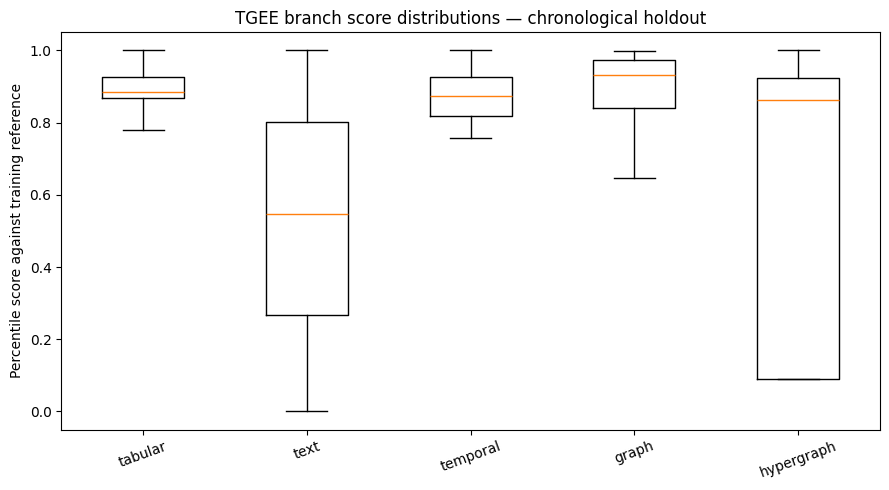

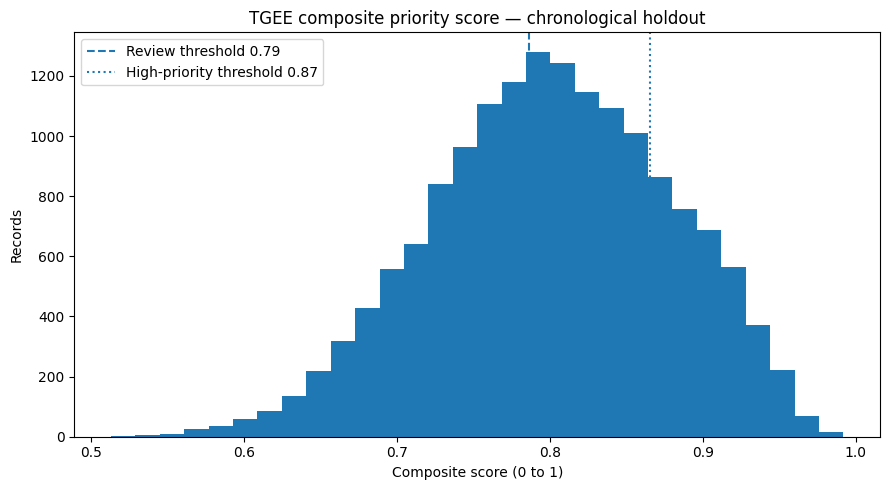

In [16]:
# Visual summaries for the final report.
fig, ax = plt.subplots(figsize=(9,5))
branch_cols=[c for c in ['tabular_score','text_score','temporal_score','graph_score','hypergraph_score'] if c in scored_df.columns]
box_data=[scored_df.loc[test_idx,c].dropna().values for c in branch_cols]
ax.boxplot(box_data, labels=[c.replace('_score','') for c in branch_cols], showfliers=False)
ax.set_title('TGEE branch score distributions — chronological holdout')
ax.set_ylabel('Percentile score against training reference')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIGURE_DIR/'branch_score_distributions.png',dpi=160,bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9,5))
ax.hist(scored_df.loc[test_idx,'tgee_priority_score'].dropna(),bins=30)
ax.axvline(review_threshold,linestyle='--',label=f'Review threshold {review_threshold:.2f}')
ax.axvline(high_threshold,linestyle=':',label=f'High-priority threshold {high_threshold:.2f}')
ax.set_title('TGEE composite priority score — chronological holdout')
ax.set_xlabel('Composite score (0 to 1)')
ax.set_ylabel('Records')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR/'tgee_holdout_score_distribution.png',dpi=160,bbox_inches='tight')
plt.show()

## 11. Save model bundle, provenance and run metadata

In [ ]:
model_bundle = {
    'project_name': 'DSA8401 Kenya PPIP Procurement Review Prioritisation',
    'model_version': '2.0.0-fy2025-2026',
    'analysis_period': FY_LABEL,
    'fy_start': str(FY_START),
    'fy_end_exclusive': str(FY_END_EXCLUSIVE),
    'python_version': platform.python_version(),
    'numpy_version': np.__version__,
    'pandas_version': pd.__version__,
    'sklearn_version': __import__('sklearn').__version__,
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'data_mode': DATA_MODE,
    'source_files_selected': SOURCE_FILES,
    'unique_ocids': int(df['ocid'].nunique()),
    'tabular_model': branch_results['tabular']['model'],
    'tabular_feature_cols': TABULAR_NUMERIC + TABULAR_CATEGORICAL,
    'tabular_numeric_cols': TABULAR_NUMERIC,
    'tabular_categorical_cols': TABULAR_CATEGORICAL,
    'tabular_reference': branch_results['tabular']['reference'],
    'temporal_model': branch_results['temporal']['model'],
    'temporal_feature_cols': TEMPORAL_FEATURES,
    'temporal_reference': branch_results['temporal']['reference'],
    'graph_model': branch_results['graph']['model'],
    'graph_feature_cols': GRAPH_FEATURES,
    'graph_reference': branch_results['graph']['reference'],
    'weights': active_weights,
    'review_threshold': review_threshold,
    'high_threshold': high_threshold,
    'text_active': ('text' in branch_results),
    'hypergraph_active': ('hypergraph' in branch_results),
    'hypergraph_coverage': hypergraph_coverage,
    'hypergraph_feature_cols': HYPERGRAPH_FEATURES,
    'source_manifest': source_manifest,
    'cutoff_date': str(cutoff_date),
    'score_semantics': 'relative review-priority percentile; not a fraud probability',
}
if 'text' in branch_results:
    model_bundle.update({
        'text_detector': branch_results['text']['model'],
        'text_vectorizer': branch_results['text']['vectorizer'],
        'text_svd': branch_results['text']['svd'],
        'text_reference': branch_results['text']['reference'],
    })
if 'hypergraph' in branch_results:
    model_bundle.update({
        'hypergraph_model': branch_results['hypergraph']['model'],
        'hypergraph_reference': branch_results['hypergraph']['reference'],
    })
if proxy_champion is not None:
    model_bundle['proxy_classifier'] = proxy_champion
    model_bundle['proxy_feature_cols'] = PROXY_FEATURES
    model_bundle['proxy_label_warning'] = (
        'Predicts agreement with rule-generated proxy labels only; '
        'not verified fraud outcomes.'
    )

In [ ]:
bundle_path = ARTIFACT_DIR/'tgee_fy2025_2026_model_bundle.joblib'
joblib.dump(model_bundle,bundle_path)


In [ ]:
metadata = {
    'data_mode':DATA_MODE,
    'analysis_period':FY_LABEL,
    'fy_start':str(FY_START),
    'fy_end_exclusive':str(FY_END_EXCLUSIVE),
    'source_files_selected':SOURCE_FILES,
    'unique_ocids':int(df['ocid'].nunique()),
    'source_manifest':source_manifest,
    'records_loaded':len(all_releases),
    'raw_extracted_release_rows':raw_extracted_rows,
    'fy_cohort_release_rows':fy_cohort_release_rows,
    'excluded_outside_fy':raw_extracted_rows - fy_cohort_release_rows,
    'collapsed_prior_release_versions':collapsed_release_revisions,
    'process_snapshots':len(df),
    'train_records':len(train_idx),
    'holdout_records':len(test_idx),
    'cutoff_date':str(cutoff_date),
    'hypergraph_coverage':hypergraph_coverage,
    'hypergraph_eligible':hypergraph_eligible,
    'active_branches':active_branches,
    'active_weights':active_weights,
    'review_threshold':review_threshold,
    'high_priority_threshold':high_threshold,
    'proxy_classifier_trained':proxy_champion is not None,
    'model_bundle_sha256':hashlib.sha256(bundle_path.read_bytes()).hexdigest(),
    'score_interpretation':'Relative review-priority score; not a calibrated probability or legal finding.'
}
(ARTIFACT_DIR/'fy2025_2026_run_metadata.json').write_text(json.dumps(metadata,indent=2,default=str),encoding='utf-8')


In [ ]:
print('Saved:',bundle_path)
print('SHA-256:',metadata['model_bundle_sha256'])
print('Saved outputs:')
for p in [TABLE_DIR/'data_quality_audit.csv',TABLE_DIR/'unsupervised_model_comparison.csv',
          TABLE_DIR/'branch_ablation.csv',REPORT_DIR/'holdout_review_queue.csv',
          PROCESSED_DIR/'scored_process_snapshots.csv',ARTIFACT_DIR/'fy2025_2026_run_metadata.json']:
    print(' -',p.relative_to(PROJECT_ROOT),p.stat().st_size,'bytes')

## 12. Key methodological decisions and limitations

- **No verified outcome labels:** the main model is an anomaly-prioritisation system. It does not report fraud precision, recall, F1, ROC-AUC, PR-AUC or probability calibration.
- **Weak labels are secondary only:** the optional supervised benchmark predicts a transparent rule-generated proxy label, and the reported classification metrics measure agreement with that rubric only.
- **Chronological evaluation:** the holdout contains later process snapshots. The model, text vocabulary, imputation, score references and review thresholds are fitted on the earlier period.
- **Point-in-time relationships:** buyer-supplier and bidder co-participation features are calculated from prior records before the current process updates the history state.
- **Conditional hypergraph:** bidder co-participation is enabled only when the data contain enough identifiable multi-tenderer records. Missing tenderers are never imputed as known competitors.
- **No GCN is claimed:** this implementation uses classical anomaly detectors, temporal history features, and graph / co-participation statistics. A graph convolutional network or neural hypergraph model would be a separate extension requiring adequate identity coverage and independent validation.
- **Benford's Law:** the digit test is an exploratory diagnostic, not proof of threshold manipulation.
- **Human review:** review-band thresholds are capacity settings, not legal thresholds. Reviewers need source-document access and independent corroboration before drawing conclusions.

## Reproducibility note

Run this notebook from the project root (or use `bash run_pipeline.sh`). The notebook stores all empirical outputs, source hashes and a serialised model bundle. The synthetic fixture validates code paths only. Replace it with official PPIP/OCDS files before reporting empirical findings.